# Notebook 02 — Estatísticas descritivas e comparações entre grupos

Este notebook lê a base analítica produzida pelo Notebook 01 e gera as tabelas descritivas da dissertação:

| Tabela | Conteúdo |
| --- | --- |
| Q4 | Estatísticas descritivas da proficiência |
| Q5 e Figura 5 | Proficiência por raça/cor |
| Q6 | Características socioeconômicas por raça/cor |
| Q7 | Proficiência por sexo, incluindo os estudantes que optaram por não declarar o sexo |
| Q8 | Atributos individuais por sexo |
| Q9 | Proficiência por pretensão futura |
| Q10 | Conhecimento da escolaridade dos responsáveis e proficiência |
| Q11 | Convivência com os responsáveis e proficiência |
| Q-EMI | Ensino Médio tradicional e integrado |

**Critérios adotados em todas as tabelas**

- **Respostas válidas.** As estatísticas de cada variável usam apenas as respostas válidas. Os estudantes sem resposta aparecem numa linha própria, quando a variável define os grupos, para que os totais fechem.
- **Escalas.** A proficiência é apresentada na métrica original do SAEB e na escala de pontos do SAEB (`proficiencia_saeb`).
- **Testes.** As diferenças entre grupos são testadas por regressão da variável de interesse sobre os grupos, com **erros-padrão agrupados por escola**. Esse procedimento é equivalente a um teste de diferença de médias, mas considera que estudantes da mesma escola tendem a ser mais parecidos entre si, como na regressão principal. Para comparações com mais de dois grupos, informa-se o teste conjunto (Wald) e a diferença de cada grupo em relação ao grupo de referência.
- **Tamanho de efeito.** d de Cohen para dois grupos e eta² para mais de dois grupos.
- **Pesos amostrais.** Os estudantes pertencem à parte censitária do SAEB. As tabelas não são ponderadas; o Q4 mostra a média ponderada pelo peso do aluno para comparação.

**Entradas:** `base_analitica.parquet` e `grupo_sexo_nao_declarado.parquet` (gerados pelo Notebook 01).
**Saídas:** `tabelas_descritivas.xlsx` e `figura5_proficiencia_raca.png`.

## 0. Configuração e funções auxiliares

In [14]:
import sys, numpy as np, pandas as pd
import statsmodels, statsmodels.formula.api as smf
import matplotlib, matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PASTA = '/content/drive/MyDrive/dissertacao/'   # ajuste para a sua pasta
except ImportError:
    PASTA = './'

print({'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
       'statsmodels': statsmodels.__version__, 'matplotlib': matplotlib.__version__})

base = pd.read_parquet(PASTA + 'base_analitica.parquet')
nd = pd.read_parquet(PASTA + 'grupo_sexo_nao_declarado.parquet')
assert len(base) == 22996, f'A base analítica tem {len(base)} estudantes; esperado 22.996.'
print('Base analítica:', len(base), '| Não declararam o sexo (complementar):', len(nd))

FATOR_SAEB = 55.093   # 1 unidade da métrica original = 55,093 pontos da escala SAEB (Notebook 01)
Y, YS = 'proficiencia', 'proficiencia_saeb'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'python': '3.13.16', 'pandas': '2.2.3', 'numpy': '2.1.3', 'statsmodels': '0.15.0', 'matplotlib': '3.10.0'}
Base analítica: 22996 | Não declararam o sexo (complementar): 202


In [15]:
def validos(df, v):
    """Estudantes com resposta válida em v (exclui branco, nulo e, na escolaridade, "não sei")."""
    m = pd.Series(True, index=df.index)
    if 'ausente_' + v in df:  m &= df['ausente_' + v] == 0
    if 'nao_sabe_' + v in df: m &= df['nao_sabe_' + v] == 0
    return df[m]

def sig(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'

def d_cohen(a, b):
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

def eta2(df, y, g):
    media = df[y].mean()
    entre = sum(len(x) * (x[y].mean() - media) ** 2 for _, x in df.groupby(g))
    return entre / ((df[y] - media) ** 2).sum()

def teste(df, y, g, ref):
    """Regressão de y sobre os grupos de g (referência = ref), com erros-padrão agrupados por escola.
    Retorna o p-valor do teste conjunto e um DataFrame com diferença e p-valor de cada grupo."""
    d = df[[y, g, 'id_escola']].dropna()
    r = smf.ols(f'{y} ~ C({g}, Treatment({ref!r}))', d).fit(cov_type='cluster', cov_kwds={'groups': d['id_escola']})
    nomes = [n for n in r.params.index if n.startswith('C(')]
    R = np.zeros((len(nomes), len(r.params)))
    for i, n in enumerate(nomes): R[i, list(r.params.index).index(n)] = 1
    p_global = float(r.wald_test(R, scalar=True).pvalue)
    difs = pd.DataFrame({'Grupo': [n.split('[T.')[1].rstrip(']') for n in nomes],
                         'Diferença': [r.params[n] for n in nomes],
                         'p-valor': [r.pvalues[n] for n in nomes]})
    return p_global, difs

def resumo(df, g, ordem=None):
    t = df.groupby(g)[[Y, YS]].agg(['size', 'mean', 'median', 'std'])
    t = pd.DataFrame({'N': t[(Y, 'size')], '%': 100 * t[(Y, 'size')] / len(df),
                      'Média': t[(Y, 'mean')], 'Mediana': t[(Y, 'median')], 'Desvio-padrão': t[(Y, 'std')],
                      'Média (pontos SAEB)': t[(YS, 'mean')]})
    t = t.loc[ordem] if ordem else t.sort_values('Média', ascending=False)
    return t.reset_index().rename(columns={g: 'Grupo'})

TABELAS = {}
def fmt_p(p):
    if pd.isna(p): return ''
    return '< 0,001' if p < 0.001 else f'{p:.3f}'.replace('.', ',')

def guardar(nome, t, arred=4):
    t = t.copy()
    for c in t.columns:
        if c.startswith('p-valor') or c.startswith('p ('):
            t[c] = t[c].map(fmt_p)
        elif pd.api.types.is_float_dtype(t[c]):
            t[c] = t[c].round(1 if ('pontos' in c or c == '%') else arred)
    TABELAS[nome] = t
    print(t.to_string(index=False))

## Q4. Estatísticas descritivas da proficiência

In [16]:
def descr(s):
    return [len(s), s.mean(), s.median(), s.std(), s.min(), s.max()]
q4 = pd.DataFrame({'Estatística': ['N', 'Média', 'Mediana', 'Desvio-padrão', 'Mínimo', 'Máximo'],
                   'Métrica original do SAEB': descr(base[Y]),
                   'Escala de pontos do SAEB': descr(base[YS])})
pond = [np.nan, np.average(base[Y], weights=base['peso_aluno']), np.nan, np.nan, np.nan, np.nan]
pond_s = [np.nan, np.average(base[YS], weights=base['peso_aluno']), np.nan, np.nan, np.nan, np.nan]
q4.loc[len(q4)] = ['Média ponderada pelo peso do aluno', pond[1], pond_s[1]]
q4['Métrica original do SAEB'] = [f'{x:,.0f}'.replace(',', '.') if i == 0 else round(x, 4) for i, x in enumerate(q4['Métrica original do SAEB'])]
q4['Escala de pontos do SAEB'] = [f'{x:,.0f}'.replace(',', '.') if i == 0 else round(x, 1) for i, x in enumerate(q4['Escala de pontos do SAEB'])]
TABELAS['Q4'] = q4
print(q4.to_string(index=False))

                       Estatística Métrica original do SAEB Escala de pontos do SAEB
                                 N                   22.996                   22.996
                             Média                   0.3547                    269.5
                           Mediana                   0.4045                    272.3
                     Desvio-padrão                   0.9134                     50.3
                            Mínimo                  -1.9627                    141.9
                            Máximo                   2.8814                    408.7
Média ponderada pelo peso do aluno                   0.3581                    269.7


## Q5 e Figura 5. Proficiência por raça/cor

In [17]:
q5 = resumo(base, 'raca_cor')
p, difs = teste(base, Y, 'raca_cor', 'Branca')
q5 = q5.merge(difs, on='Grupo', how='left')
q5['Diferença (pontos SAEB)'] = q5['Diferença'] * FATOR_SAEB
q5['Sig.'] = q5['p-valor'].map(lambda x: sig(x) if pd.notna(x) else 'ref.')
guardar('Q5', q5)
print(f'\nTeste conjunto: p = {p:.2e} | eta² = {eta2(base, Y, "raca_cor"):.4f}')
print('Diferenças em relação aos estudantes brancos; erros-padrão agrupados por escola.')

   Grupo     N    %   Média  Mediana  Desvio-padrão  Média (pontos SAEB)  Diferença p-valor  Diferença (pontos SAEB) Sig.
  Branca  7039 30.6  0.5673   0.6574         0.9155                281.2        NaN                              NaN ref.
   Parda 11962 52.0  0.3011   0.3398         0.8900                266.6    -0.2661 < 0,001                    -14.7  ***
   Preta  3234 14.1  0.1666   0.1676         0.9088                259.2    -0.4007 < 0,001                    -22.1  ***
 Amarela   512  2.2  0.1595   0.1841         0.8749                258.8    -0.4078 < 0,001                    -22.5  ***
Indígena   249  1.1 -0.2393  -0.2504         0.8385                236.8    -0.8066 < 0,001                    -44.4  ***

Teste conjunto: p = 6.22e-120 | eta² = 0.0299
Diferenças em relação aos estudantes brancos; erros-padrão agrupados por escola.


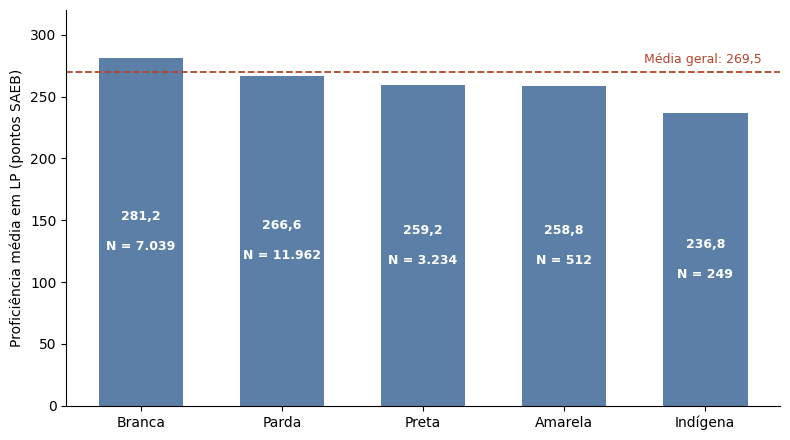

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
g = q5.sort_values('Média (pontos SAEB)', ascending=False)
barras = ax.bar(g['Grupo'], g['Média (pontos SAEB)'], color='#5b7fa6', width=0.6)
media_geral = base[YS].mean()
ax.axhline(media_geral, color='#b5452b', linestyle='--', linewidth=1.3)
ax.text(len(g) - 0.6, media_geral + 8, f'Média geral: {media_geral:.1f}'.replace('.', ','), ha='right', color='#b5452b', fontsize=9)
for bar, (_, r) in zip(barras, g.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2,
            f"{r['Média (pontos SAEB)']:.1f}".replace('.', ',') + f"\n\nN = {int(r['N']):,}".replace(',', '.'),
            ha='center', va='center', color='white', fontsize=9, fontweight='bold')
ax.set_ylabel('Proficiência média em LP (pontos SAEB)')
ax.set_ylim(0, 320)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(PASTA + 'figura5_proficiencia_raca.png', dpi=300)
plt.show()

## Q6. Características socioeconômicas por raça/cor

Médias calculadas apenas com respostas válidas. Escolaridade em escala de 1 a 5; computadores em escala de 0 (nenhum) a 3 (três ou mais); demais itens em percentual de estudantes que possuem. O INSE é o indicador de nível socioeconômico calculado pelo INEP.

In [19]:
itens = {'Escolaridade da mãe (1 a 5)': 'escolaridade_mae', 'Escolaridade do pai (1 a 5)': 'escolaridade_pai',
         'Computadores (0 a 3)': 'qtd_computadores', 'Possui Wi-Fi (%)': 'possui_wifi',
         'Possui mesa para estudar (%)': 'possui_escrivaninha', 'Possui quarto só seu (%)': 'possui_casa_quarto_individual'}
ordem = list(q5['Grupo'])
linhas = []
for rot, v in itens.items():
    m = validos(base, v).groupby('raca_cor')[v].mean().reindex(ordem)
    if '(%)' in rot: m = 100 * m
    linhas.append([rot] + list(m))
linhas.append(['Não sabe a escolaridade da mãe (%)'] + list(100 * base.groupby('raca_cor')['nao_sabe_escolaridade_mae'].mean().reindex(ordem)))
linhas.append(['INSE (média)'] + list(base.groupby('raca_cor')['inse'].mean().reindex(ordem)))
q6 = pd.DataFrame(linhas, columns=['Característica'] + ordem)
guardar('Q6', q6, arred=2)

                    Característica  Branca  Parda  Preta  Amarela  Indígena
       Escolaridade da mãe (1 a 5)    3.94   3.71   3.67     3.64      3.50
       Escolaridade do pai (1 a 5)    3.47   3.22   3.19     3.16      3.22
              Computadores (0 a 3)    1.06   0.81   0.76     0.84      0.75
                  Possui Wi-Fi (%)   95.72  93.20  91.54    93.89     91.25
      Possui mesa para estudar (%)   68.07  59.17  56.25    58.15     58.61
          Possui quarto só seu (%)   70.21  63.85  62.01    63.26     61.00
Não sabe a escolaridade da mãe (%)    9.77  12.46  15.31    12.50     14.46
                      INSE (média)    5.30   4.99   4.93     5.03      4.76


## Q7. Proficiência por sexo

Inclui, como grupo complementar, os estudantes que optaram por "Não quero declarar" (categoria C da questão sobre sexo). Esse grupo não faz parte da base analítica; as comparações com ele são descritivas e complementares. O objetivo é verificar a proficiência destes estudantes que podem pertencer a um grupo que não se identifica com o sexo masculino ou feminino.

In [20]:
todos = pd.concat([base, nd], ignore_index=True)
ordem_sexo = ['Feminino', 'Masculino', 'Não declarado']
q7 = resumo(todos, 'sexo', ordem_sexo)
q7['%'] = 100 * q7['N'] / q7['N'].sum()
comparacoes = [('Feminino', 'Masculino'), ('Não declarado', 'Masculino'), ('Não declarado', 'Feminino')]
testes = []
for a, b in comparacoes:
    d = todos[todos['sexo'].isin([a, b])]
    _, dif = teste(d, Y, 'sexo', b)
    testes.append({'Comparação': f'{a} × {b}', 'Diferença': dif['Diferença'][0],
                   'Diferença (pontos SAEB)': dif['Diferença'][0] * FATOR_SAEB,
                   'p-valor': dif['p-valor'][0], 'Sig.': sig(dif['p-valor'][0]),
                   'd de Cohen': d_cohen(d.loc[d.sexo == a, Y], d.loc[d.sexo == b, Y])})
guardar('Q7', q7)
print()
guardar('Q7 testes', pd.DataFrame(testes))

        Grupo     N    %  Média  Mediana  Desvio-padrão  Média (pontos SAEB)
     Feminino 12669 54.6 0.4645   0.5320         0.8713                275.6
    Masculino 10327 44.5 0.2200   0.2317         0.9452                262.1
Não declarado   202  0.9 0.3857   0.4559         0.9583                271.2

               Comparação  Diferença  Diferença (pontos SAEB) p-valor Sig.  d de Cohen
     Feminino × Masculino     0.2444                     13.5 < 0,001  ***      0.2700
Não declarado × Masculino     0.1657                      9.1   0,005   **      0.1752
 Não declarado × Feminino    -0.0787                     -4.3   0,183   ns     -0.0902


## Q8. Atributos individuais por sexo

In [21]:
atributos = {'Idade (anos)': 'idade', 'Reprovação (0 a 2)': 'reprovacao',
             'Tempo de estudos (0 a 3)': 'tempo_estudos', 'Tempo em cursos (0 a 3)': 'tempo_cursos',
             'Tempo de trabalho doméstico (0 a 3)': 'tempo_trabalho_domestico',
             'Tempo de trabalho fora de casa (0 a 3)': 'tempo_trabalho',
             'Q23b: 0 = concordo totalmente a 3 = discordo totalmente': 'aluno_motivacao_aplicar_aprendizado'}
linhas = []
for rot, v in atributos.items():
    d = validos(todos, v)
    medias = d.groupby('sexo')[v].mean()
    lin = {'Atributo': rot, **{f'{s} (média)': medias.get(s) for s in ordem_sexo}}
    for a, b in comparacoes:
        dd = d[d['sexo'].isin([a, b])]
        _, dif = teste(dd, v, 'sexo', b)
        SIG = {'Feminino': 'F', 'Masculino': 'M', 'Não declarado': 'ND'}
        lin[f'p ({SIG[a]} × {SIG[b]})'] = dif['p-valor'][0]
    linhas.append(lin)
guardar('Q8', pd.DataFrame(linhas), arred=3)
print('\nF = feminino; M = masculino; ND = não declarado. Médias com respostas válidas; p-valores com erros-padrão agrupados por escola.')

                                               Atributo  Feminino (média)  Masculino (média)  Não declarado (média) p (F × M) p (ND × M) p (ND × F)
                                           Idade (anos)            17.585             17.660                 17.634   < 0,001      0,583      0,303
                                     Reprovação (0 a 2)             0.098              0.172                  0.166   < 0,001      0,819      0,016
                               Tempo de estudos (0 a 3)             1.474              1.159                  1.219   < 0,001      0,411    < 0,001
                                Tempo em cursos (0 a 3)             1.069              0.971                  1.323   < 0,001    < 0,001      0,003
                    Tempo de trabalho doméstico (0 a 3)             2.291              1.781                  2.025   < 0,001    < 0,001    < 0,001
                 Tempo de trabalho fora de casa (0 a 3)             1.601              2.066                  1.

## Q9. Proficiência por pretensão futura

In [22]:
q9 = resumo(base, 'pretensao_futura')
p, difs = teste(base, Y, 'pretensao_futura', 'Somente estudar')
q9 = q9.merge(difs, on='Grupo', how='left')
q9['Diferença (pontos SAEB)'] = q9['Diferença'] * FATOR_SAEB
q9['Sig.'] = q9['p-valor'].map(lambda x: sig(x) if pd.notna(x) else 'ref.')
guardar('Q9', q9)
print(f'\nTeste conjunto: p = {p:.2e} | eta² = {eta2(base, Y, "pretensao_futura"):.4f}')
print('Diferenças em relação a "Somente estudar"; erros-padrão agrupados por escola.')

              Grupo     N    %   Média  Mediana  Desvio-padrão  Média (pontos SAEB)  Diferença p-valor  Diferença (pontos SAEB) Sig.
    Somente estudar  1570  6.8  0.5457   0.6623         1.0055                280.0        NaN                              NaN ref.
Estudar e trabalhar 17212 74.8  0.4428   0.5119         0.8824                274.4    -0.1029 < 0,001                     -5.7  ***
     Ainda não sabe  2303 10.0  0.0562   0.0311         0.8966                253.1    -0.4895 < 0,001                    -27.0  ***
  Somente trabalhar  1911  8.3 -0.2362  -0.2946         0.8197                237.0    -0.7819 < 0,001                    -43.1  ***

Teste conjunto: p = 1.14e-250 | eta² = 0.0554
Diferenças em relação a "Somente estudar"; erros-padrão agrupados por escola.


## Q10. Conhecimento da escolaridade dos responsáveis e proficiência

Três grupos para cada responsável: respondeu a escolaridade, respondeu "Não sei" e deixou sem resposta (branco ou nulo).

In [23]:
def grupo_escol(df, v):
    return np.select([df['nao_sabe_' + v] == 1, df['ausente_' + v] == 1], ['Não sabe', 'Sem resposta'], 'Respondeu')

linhas, testes10 = [], []
for rot, v in [('mãe', 'escolaridade_mae'), ('pai', 'escolaridade_pai')]:
    d = base.assign(grupo=grupo_escol(base, v))
    r = resumo(d, 'grupo', ['Respondeu', 'Não sabe', 'Sem resposta'])
    r.insert(0, 'Responsável', rot)
    linhas.append(r)
    _, dif = teste(d, Y, 'grupo', 'Respondeu')
    for _, x in dif.iterrows():
        testes10.append({'Responsável': rot, 'Comparação': f"{x['Grupo']} × Respondeu",
                         'Diferença (pontos SAEB)': x['Diferença'] * FATOR_SAEB, 'p-valor': x['p-valor'],
                         'Sig.': sig(x['p-valor']),
                         'd de Cohen': d_cohen(d.loc[d.grupo == x['Grupo'], Y], d.loc[d.grupo == 'Respondeu', Y])})
ambos = base[(base.nao_sabe_escolaridade_mae == 1) & (base.nao_sabe_escolaridade_pai == 1)]
linhas.append(pd.DataFrame([{'Responsável': 'ambos', 'Grupo': 'Não sabe nenhuma das duas', 'N': len(ambos),
                             '%': 100 * len(ambos) / len(base), 'Média': ambos[Y].mean(), 'Mediana': ambos[Y].median(),
                             'Desvio-padrão': ambos[Y].std(), 'Média (pontos SAEB)': ambos[YS].mean()}]))
guardar('Q10', pd.concat(linhas, ignore_index=True))
print()
guardar('Q10 testes', pd.DataFrame(testes10))

Responsável                     Grupo     N    %   Média  Mediana  Desvio-padrão  Média (pontos SAEB)
        mãe                 Respondeu 19997 87.0  0.4089   0.4701         0.9107                272.5
        mãe                  Não sabe  2773 12.1  0.0019  -0.0187         0.8466                250.1
        mãe              Sem resposta   226  1.0 -0.1178  -0.1159         0.8345                243.5
        pai                 Respondeu 17363 75.5  0.4246   0.4880         0.9135                273.4
        pai                  Não sabe  5398 23.5  0.1515   0.1762         0.8750                258.3
        pai              Sem resposta   235  1.0 -0.1466  -0.2138         0.9137                241.9
      ambos Não sabe nenhuma das duas  2072  9.0 -0.0472  -0.0771         0.8385                247.4

Responsável               Comparação  Diferença (pontos SAEB) p-valor Sig.  d de Cohen
        mãe     Não sabe × Respondeu                    -22.4 < 0,001  ***     -0.4506
        m

## Q11. Convivência com os responsáveis e proficiência

Três grupos para cada responsável: mora, não mora e sem resposta. O teste compara "mora" e "não mora" entre as respostas válidas.

In [24]:
linhas, testes11 = [], []
for rot, v in [('mãe', 'mora_mae'), ('pai', 'mora_pai')]:
    grupo = np.select([base['ausente_' + v] == 1, base[v] == 1], ['Sem resposta', 'Mora'], 'Não mora')
    d = base.assign(grupo=grupo)
    r = resumo(d, 'grupo', ['Mora', 'Não mora', 'Sem resposta'])
    r.insert(0, 'Responsável', rot)
    linhas.append(r)
    dv = d[d.grupo != 'Sem resposta']
    _, dif = teste(dv, Y, 'grupo', 'Não mora')
    testes11.append({'Responsável': rot, 'Comparação': 'Mora × Não mora',
                     'Diferença (pontos SAEB)': dif['Diferença'][0] * FATOR_SAEB,
                     'p-valor': dif['p-valor'][0], 'Sig.': sig(dif['p-valor'][0]),
                     'd de Cohen': d_cohen(dv.loc[dv.grupo == 'Mora', Y], dv.loc[dv.grupo == 'Não mora', Y])})
guardar('Q11', pd.concat(linhas, ignore_index=True))
print()
guardar('Q11 testes', pd.DataFrame(testes11))

Responsável        Grupo     N    %   Média  Mediana  Desvio-padrão  Média (pontos SAEB)
        mãe         Mora 18379 79.9  0.4049   0.4603         0.9142                272.3
        mãe     Não mora  3153 13.7  0.2408   0.2808         0.8715                263.3
        mãe Sem resposta  1464  6.4 -0.0308  -0.0741         0.8766                248.3
        pai         Mora 15226 66.2  0.4092   0.4682         0.9082                272.5
        pai     Não mora  5479 23.8  0.3348   0.3812         0.8997                268.4
        pai Sem resposta  2291 10.0  0.0398   0.0120         0.9144                252.2

Responsável      Comparação  Diferença (pontos SAEB) p-valor Sig.  d de Cohen
        mãe Mora × Não mora                      9.0 < 0,001  ***      0.1807
        pai Mora × Não mora                      4.1 < 0,001  ***      0.0822


## Q-EMI. Ensino Médio tradicional e integrado

A base inclui estudantes do Ensino Médio tradicional e do integrado (códigos 12 e 13 do SAEB). Esta tabela descreve os dois grupos e serve de apoio ao teste de sensibilidade da regressão sem os estudantes do integrado.

In [25]:
d = base.assign(modalidade=np.where(base.em_integrado == 1, 'Integrado', 'Tradicional'))
qe = resumo(d, 'modalidade', ['Tradicional', 'Integrado'])
qe['Escolas'] = [d.loc[d.modalidade == m, 'id_escola'].nunique() for m in qe['Grupo']]
qe['INSE médio'] = [d.loc[d.modalidade == m, 'inse'].mean() for m in qe['Grupo']]
_, dif = teste(d, Y, 'modalidade', 'Tradicional')
qe['Diferença (pontos SAEB)'] = [np.nan, dif['Diferença'][0] * FATOR_SAEB]
qe['p-valor'] = [np.nan, dif['p-valor'][0]]
guardar('Q-EMI', qe)

      Grupo     N    %  Média  Mediana  Desvio-padrão  Média (pontos SAEB)  Escolas  INSE médio  Diferença (pontos SAEB) p-valor
Tradicional 21711 94.4 0.3253   0.3671         0.9097                267.9      390      5.0614                      NaN        
  Integrado  1285  5.6 0.8507   0.9263         0.8288                296.9       18      5.2892                     28.9 < 0,001


## Exportação

In [26]:
with pd.ExcelWriter(PASTA + 'tabelas_descritivas.xlsx') as xw:
    for nome, t in TABELAS.items():
        t.to_excel(xw, sheet_name=nome, index=False)
print('Tabelas salvas em', PASTA + 'tabelas_descritivas.xlsx')
print('Figura salva em', PASTA + 'figura5_proficiencia_raca.png')

Tabelas salvas em /content/drive/MyDrive/dissertacao/tabelas_descritivas.xlsx
Figura salva em /content/drive/MyDrive/dissertacao/figura5_proficiencia_raca.png
